# Demo: sequences <-> networks
The following notebook provides a demonstration how the ts2g2 library can be used to convert time series into graphs and graphs into time series. To that end, we use a dataset with the history of daily prices of Amazon stock (AMZN). All the column descriptions are provided. Currency is USD.

In [61]:
import os
import sys
nb_dir = os.path.split(os.getcwd())[0]
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [62]:
import os
import csv
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pipeline import T2G2Pipeline
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder

## Loading data 

We first load the dataset :)

In [63]:
amazon_data = pd.read_csv(os.path.join(os.getcwd(), "amazon", "AMZN.csv"))

To properly use the ‘Date’ column, we convert it to datetime format and ensure the dates are recognized as date objects. We then set the ‘Date’ column as the index of the DataFrame. This creates a time-series structure, facilitating analysis and visualization over time.

In [64]:
amazon_data["Date"] = pd.to_datetime(amazon_data["Date"])
amazon_data.set_index("Date", inplace=True)

# How does the time series look like?

In [65]:
def plot_timeseries(sequence, title, x_legend, y_legend, color):
    plt.figure(figsize=(10, 6))
    plt.plot(sequence, linestyle='-', color=color)
    
    plt.title(title)
    plt.xlabel(x_legend)
    plt.ylabel(y_legend)
    plt.grid(True)
    plt.show()

In [66]:

def plot_timeseries_sequence(df_column, title, x_legend, y_legend, color='black'):
    # Accepts pandas Series / DataFrame column / list / 1D numpy
    if hasattr(df_column, "to_numpy"):
        sequence = df_column.to_numpy()
    else:
        sequence = np.asarray(df_column)
    sequence = np.ravel(sequence).astype(float)  # ensure 1-D

    plot_timeseries(sequence, title, x_legend, y_legend, color)

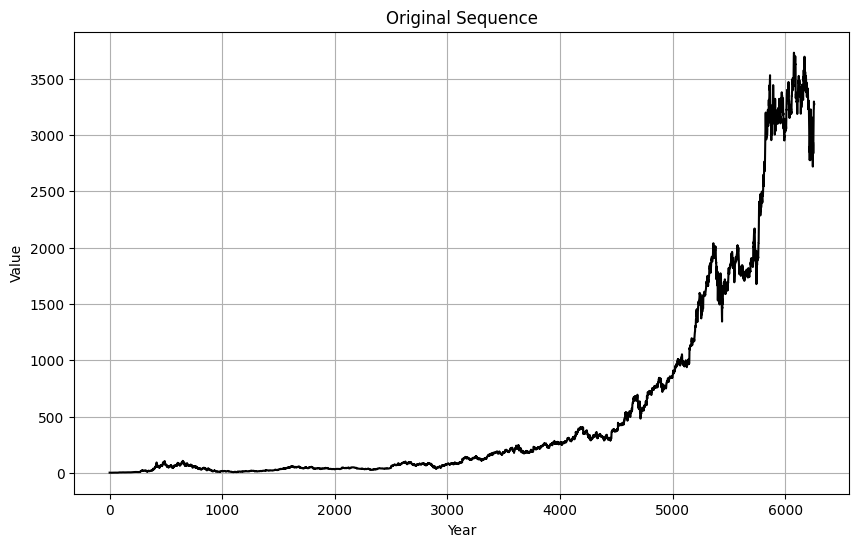

In [67]:
plot_timeseries_sequence(amazon_data["Close"], "Original Sequence", "Year", "Value")

Given the great length of the timeseries, let's focus on some sub-segments, so that we can better appreciate its behavior.

In [68]:
segment_1 = amazon_data[60:120]
segment_2 = amazon_data[4000:4060]
segment_3 = amazon_data[6000:6060]

How do the plots for these segments look like?

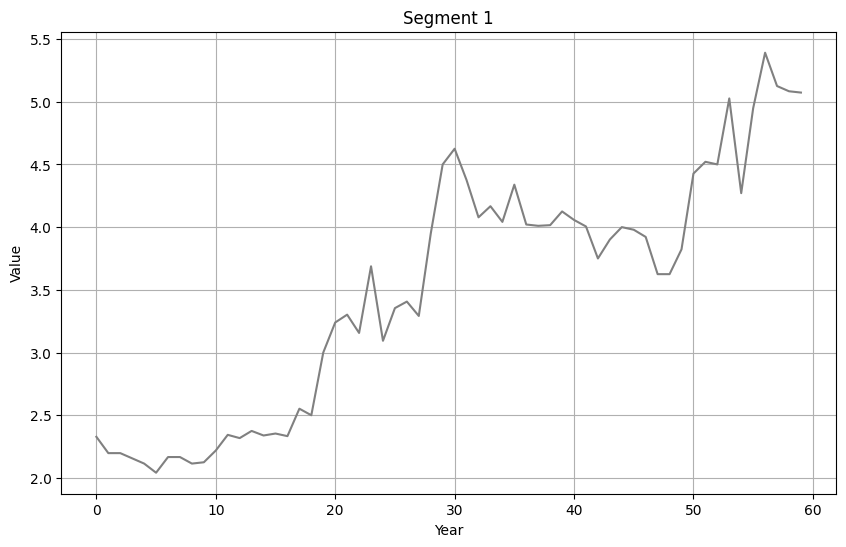

In [69]:
plot_timeseries_sequence(segment_1["Close"], "Segment 1", "Year", "Value", 'gray')

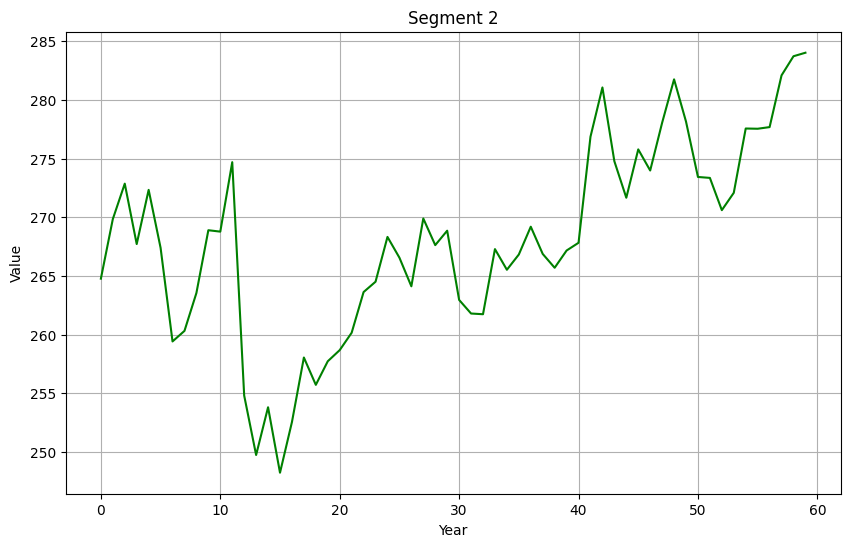

In [70]:
plot_timeseries_sequence(segment_2["Close"], "Segment 2", "Year", "Value", 'green')

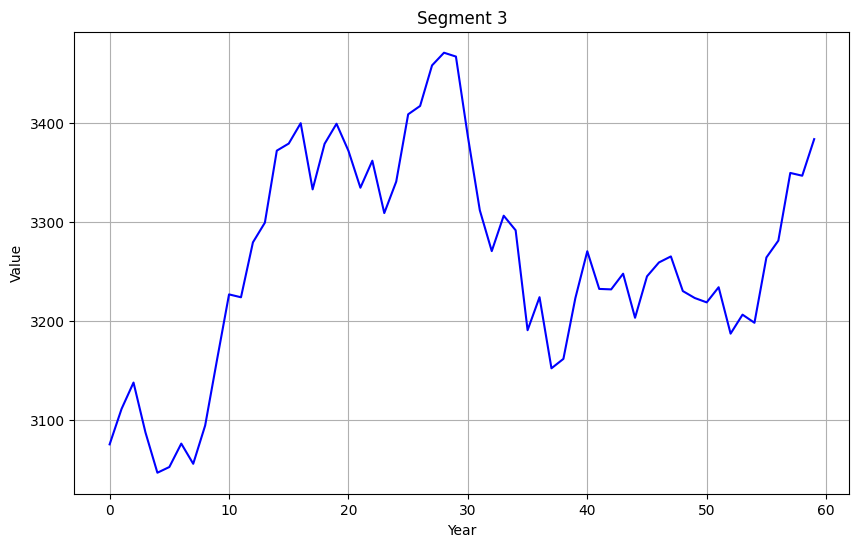

In [71]:
plot_timeseries_sequence(segment_3["Close"], "Segment 3", "Year", "Value", 'blue')

Let's turn the timeseries into networks (graphs)!

In [72]:
import numpy as np
import networkx as nx


def sequence_to_graph(column, color):
    if hasattr(column, "to_numpy"):
        arr = column.to_numpy()
    else:
        arr = np.asarray(column)
    arr = np.ravel(arr).astype(float)

    builder_cls = get_ts2g_strategy_builder(method="natural_visibility")
    ts2g_strategy = builder_cls().get_strategy()

    pipe = T2G2Pipeline().load_timeseries(arr).to_graph(ts2g_strategy)
    G = pipe.get_Graph()

    pos = nx.spring_layout(G, seed=1)
    node_colors = [color] * G.number_of_nodes()
    edge_colors = [data.get("color", "#66ff66") for _, _, data in G.edges(data=True)]
    weights = [data.get("weight", 1.0) for _, _, data in G.edges(data=True)]
    if weights:
        wmax, wmin = max(weights), min(weights)
        widths = [1.0 if wmax == wmin else (1 + 4*(w - wmin)/(wmax - wmin)) for w in weights]
    else:
        widths = None

    nx.draw(G, pos, node_size=40, node_color=node_colors, edge_color=edge_colors, width=widths)
    return G

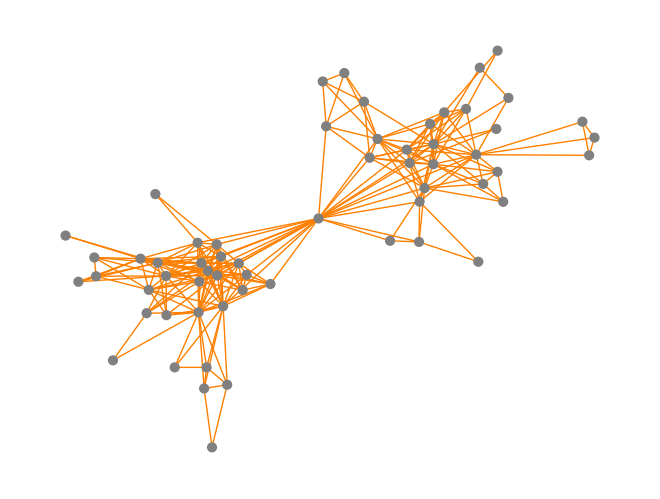

In [73]:
sequence_to_graph(segment_1["Close"], 'gray')

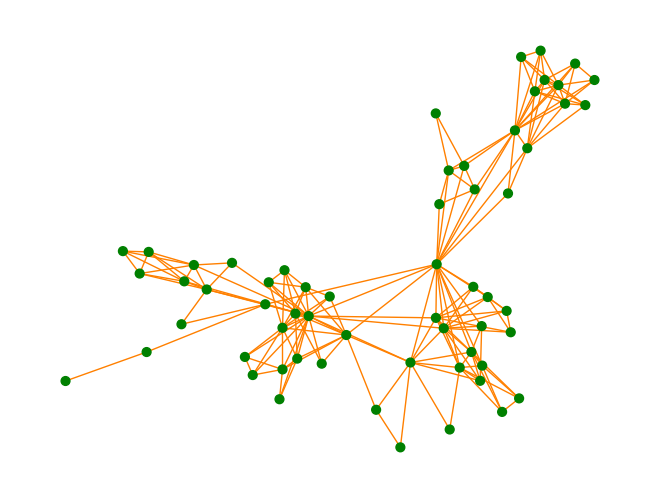

In [74]:
sequence_to_graph(segment_2["Close"], 'green')

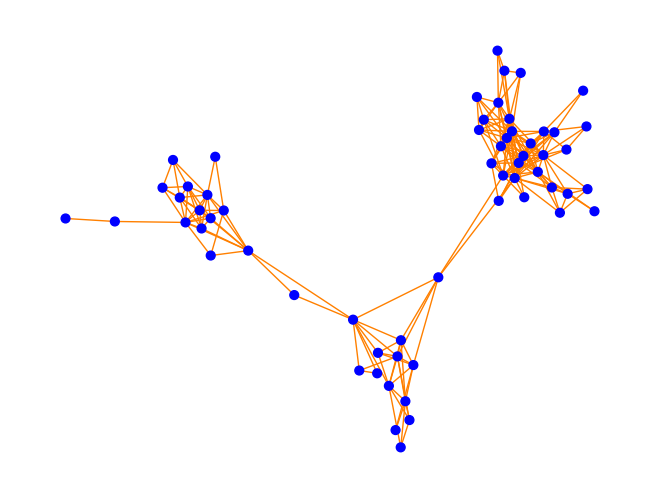

In [75]:
sequence_to_graph(segment_3["Close"], 'blue')

They look quite different! Many different strategies for converting timeseries into graphs exist:
 - TimeseriesEdgeVisibilityConstraintsNatural
 - TimeseriesEdgeVisibilityConstraintsHorizontal
 - TimeseriesEdgeVisibilityConstraintsVisibilityAngle

Now let's try to create a sequence generator, based on a graph. We will first divide each sequence into train/test sets.

In [76]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

from pipeline import T2G2Pipeline
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.g2ts import get_g2ts_strategy
from strategies.g2ts import (
    StrategySelectNextNodeRandomWithRestart,
    StrategyNextValueInNodeRoundRobin,
)

def generate_sequence(df, reference_column, color):
    # 1) split to train / test
    df_train, df_test = train_test_split(df, test_size=0.2, random_state=100, shuffle=False)
    train_series = np.asarray(df_train[reference_column]).ravel().astype(float)

    # 2) TS -> Graph (natural visibility by default)
    ts2g_builder = get_ts2g_strategy_builder(method="natural_visibility")
    ts2g_strategy = ts2g_builder().get_strategy()

    pipe = T2G2Pipeline().load_timeseries(train_series).to_graph(ts2g_strategy)

    # 3) Graph -> Sequence (plain g2ts; random-walk-with-restart for nodes; round-robin for values)
    test_length = len(df_test)
    g2ts_cls = get_g2ts_strategy("plain")
    g2ts = (
        g2ts_cls()
        .next_node_strategy(StrategySelectNextNodeRandomWithRestart())
        .next_value_strategy(StrategyNextValueInNodeRoundRobin())
        .ts_length(test_length)
    )
    sequences = pipe.to_timeseries(g2ts).sequences
    seq = sequences[0] if isinstance(sequences, list) else sequences

    # 4) stitch predictions back to full index for plotting
    y_true = df[reference_column].values
    y_pred = [None] * len(df_train) + list(seq)
    dfx = pd.DataFrame({"y_true": y_true, "y_pred": y_pred}, index=df.index)

    # 5) plot
    plt.figure(figsize=(10, 6))
    plt.plot(dfx["y_true"], linestyle='-.', color=color, label="True")
    plt.plot(dfx["y_pred"], linestyle='-',  color='black', label="Pred")
    plt.title("Random Walk With Restart (g2ts: plain)")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.grid(False)
    plt.legend()
    plt.show()

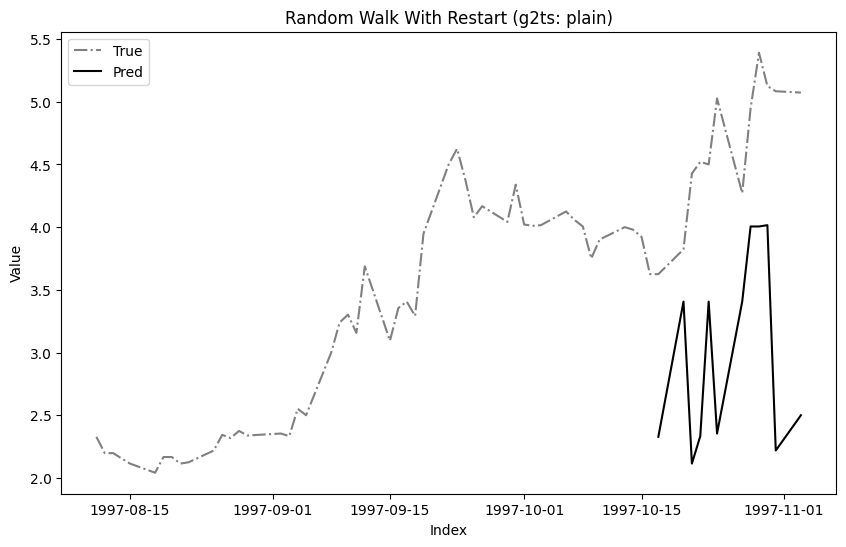

In [77]:
generate_sequence(segment_1, 'Close', 'gray')

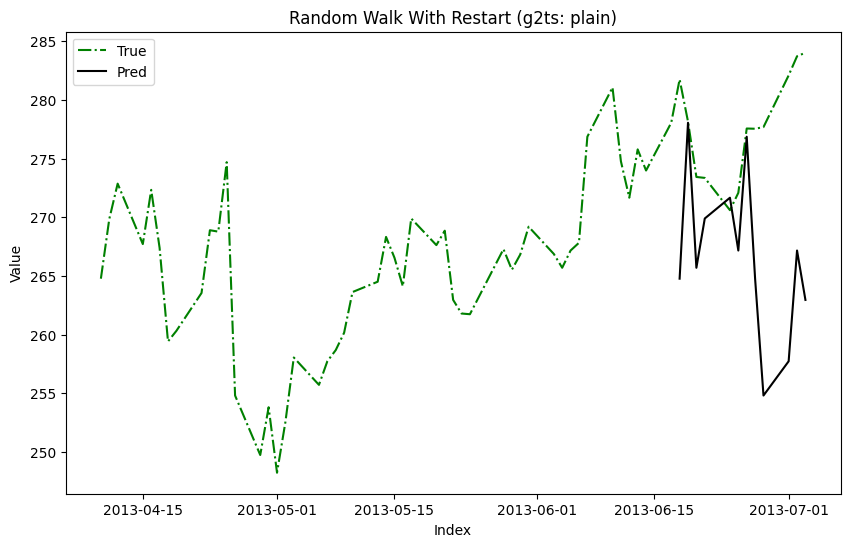

In [78]:
generate_sequence(segment_2, 'Close', 'green')

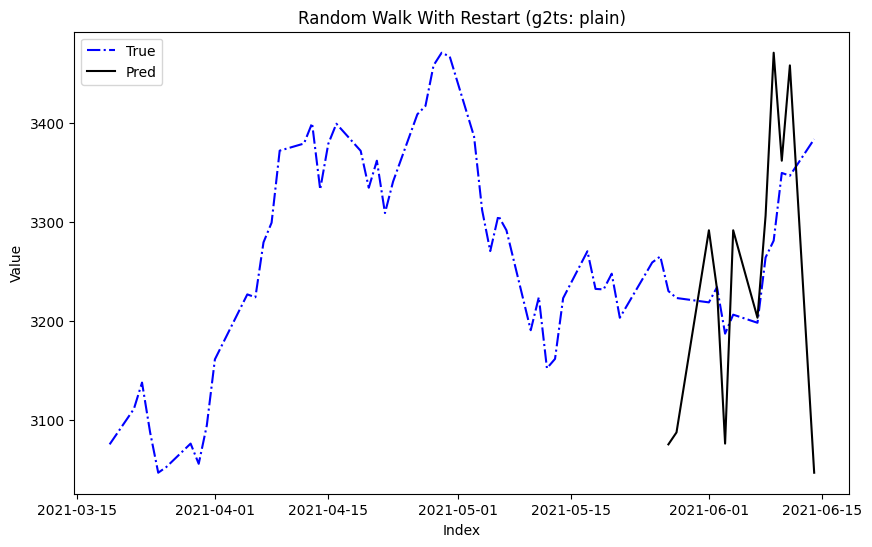

In [79]:
generate_sequence(segment_3, 'Close', 'blue')

Many additional strategies for converting graphs to timeseries exist: 
 - RandomWalkWithRestartSequenceGenerationStrategy
 - RandomWalkSequenceGenerationStrategy
 - RandomNodeSequenceGenerationStrategy
 - RandomDegreeNodeSequenceGenerationStrategy
 - RandomDegreeNodeSequenceGenerationStrategy
 - RandomNodeNeighbourSequenceGenerationStrategy